        # Lesson 7.1 · What Is a Time Series?
        ### Trend, seasonality, cycles, noise, stationarity and autocorrelation

        | | |
        |---|---|
        | ⏱️ **Time** | about 75 minutes |
        | 📚 **Before you start** | Basic pandas and matplotlib (Phases 1-6) |
        | 🧪 **Format** | lesson → worked examples → exercises with hints → recap |

        ## 🎯 What you will be able to do after this notebook
        - Explain why *order* is the single most important property of time-series data
- Separate a price series into **trend**, **seasonality**, **cyclical** movement and **noise**
- Test and fix **stationarity** with the ADF test and differencing
- Compute and read **ACF** and **PACF** plots, and relate them to **lag observations**

> 🌾 **The story so far.** The farmers' cooperative asks one question: *"If we store our tomatoes for six weeks, will we get a better price?"* To answer it you must first understand what the price series is *made of*.

In [1]:
import sys, pathlib, warnings
# Find the course folder (works no matter where Jupyter was started)
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src" / "agrilab.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import agrilab as ag          # our helper library: src/agrilab.py

from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
warnings.filterwarnings("ignore")   # (after imports: statsmodels re-enables its own warnings when imported)
ag.setup_plots()
ag.set_seed(42)
print("Setup complete. Course folder:", ROOT.name)

Setup complete. Course folder: course


## 1 · Why time series is different

Imagine I hand you a stack of index cards, each with one day's tomato price. If I **shuffle the cards**, a
house-price regression doesn't care: each house is independent. But a time series *does* care:
yesterday's price tells you something about today's. The **order is the information.**

> **Definition.** A *time series* is a sequence of observations $y_1, y_2, \dots, y_T$ recorded at (usually equally spaced) points in time.

Three questions we ask of time series, in increasing ambition:

| Goal | Question | This phase |
|---|---|---|
| **Describe** | What does the pattern look like? | Notebooks 7.1–7.2 |
| **Explain** | *Why* does it move (rain? fuel? harvest?) | 7.5 (SARIMAX), 7.6 |
| **Forecast** | What happens next, and how sure are we? | 7.3–7.8 |

Let's meet our data.

In [2]:
prices = ag.load_prices()
print(prices.shape)
prices.head()

(35732, 6)


,date,market,commodity,price_per_kg,volume_tonnes,fuel_index
0,2015-01-01,Central,maize,39.82,111.0,100.4
1,2015-01-02,Central,maize,39.44,119.2,101.1
2,2015-01-03,Central,maize,39.29,73.7,101.6
3,2015-01-05,Central,maize,39.45,95.3,100.6
4,2015-01-06,Central,maize,38.98,118.5,100.7


One row = one commodity, in one market, on one day. For now we zoom into a single series:
**tomatoes at the Central market.**

Observations: 3653 | from 2015-01-01 to 2024-12-31


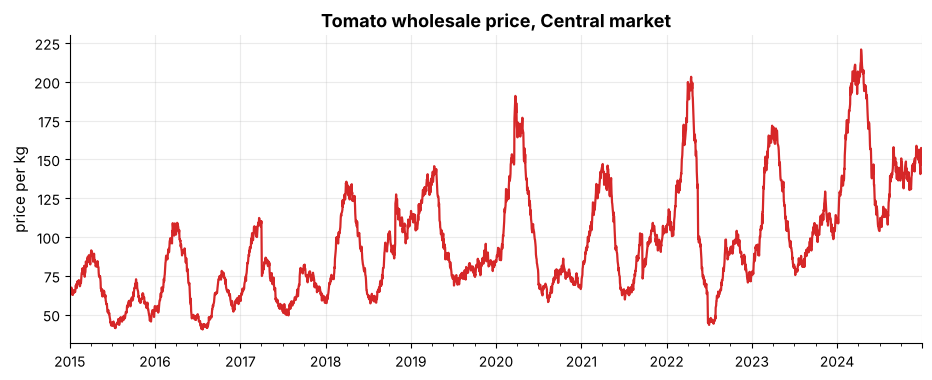

In [3]:
tomato = ag.price_series("tomato", "Central", freq="D")   # daily, gaps filled, outliers removed
print("Observations:", len(tomato), "| from", tomato.index.min().date(), "to", tomato.index.max().date())

fig, ax = plt.subplots()
tomato.plot(ax=ax, color="tab:red")
ax.set(title="Tomato wholesale price, Central market", ylabel="price per kg", xlabel="")
plt.show()

Look at it like a detective. I see (1) a slow **upward drift**, (2) a wavy pattern that **repeats yearly**,
(3) a few **sudden spikes**, and (4) day-to-day **jitter**. That is already the whole lesson in four sentences.
Let's give each its proper name.

---
## 2 · The four ingredients

| Component | Plain-English meaning | Typical cause in agriculture |
|---|---|---|
| **Trend** $T_t$ | long-run direction | inflation, population growth, rising input costs |
| **Seasonality** $S_t$ | pattern with a **fixed, known period** (calendar-driven) | planting / harvest cycle, rainy seasons, festivals |
| **Cyclicality** $C_t$ | rises & falls with **no fixed period** | multi-year droughts, price-boom/bust ("cobweb") cycles, economic cycles |
| **Noise** $\varepsilon_t$ | what is left: unpredictable | weather on the day, trader mood, measurement error |

Two classic ways to combine them:

- **Additive:** $y_t = T_t + S_t + C_t + \varepsilon_t$: seasonal swings have constant size.
- **Multiplicative:** $y_t = T_t \times S_t \times C_t \times \varepsilon_t$: seasonal swings *grow with the level*.
  Taking logs turns it into the additive form: $\log y_t = \log T_t + \log S_t + \dots$

> ⚖️ **Seasonality vs cyclicality** is the distinction students mix up most. Ask: *"Can I name the period on a calendar?"*
> Yes → seasonal (12 months). No (it was 3 years once, 5 the next) → cyclical.

### Building a series from scratch (the best way to understand it)

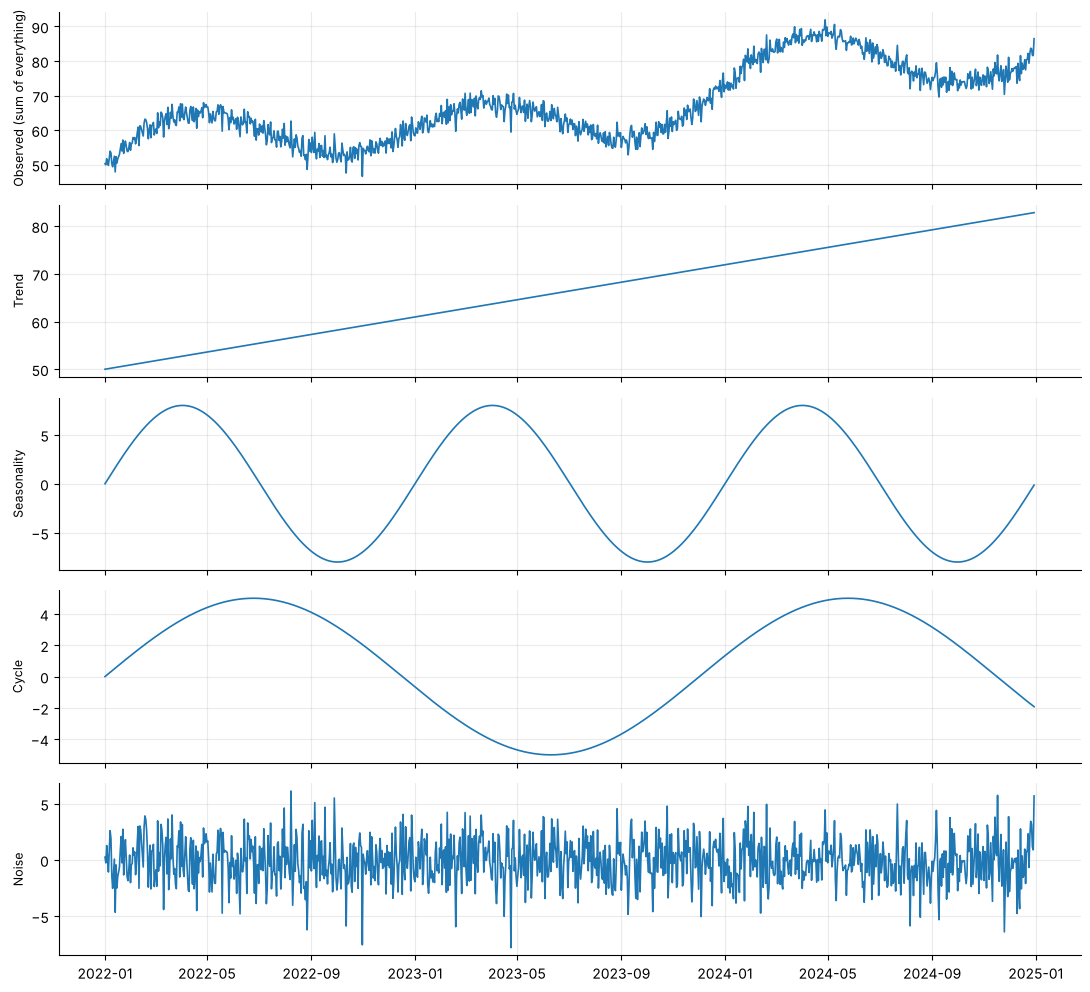

In [4]:
rng = np.random.default_rng(0)
t = np.arange(3 * 365)                                   # three years of days
trend = 50 + 0.03 * t                                    # slow climb
season = 8 * np.sin(2 * np.pi * t / 365)                 # period = 365 days
cycle = 5 * np.sin(2 * np.pi * t / 700)                  # period ~ 700 days (NOT calendar-locked)
noise = rng.normal(0, 2, len(t))
toy = pd.Series(trend + season + cycle + noise, index=pd.date_range("2022-01-01", periods=len(t)))

fig, axes = plt.subplots(5, 1, figsize=(11, 10), sharex=True)
for ax, (name, y) in zip(axes, [("Observed (sum of everything)", toy), ("Trend", trend), ("Seasonality", season),
                                ("Cycle", cycle), ("Noise", noise)]):
    ax.plot(toy.index, y, lw=1.2); ax.set_ylabel(name, fontsize=9)
plt.tight_layout(); plt.show()

> 🤔 **Pause and think.** If the seasonal swing in tomato prices gets *bigger* as prices rise over the years, should you model it as additive or multiplicative?
>
> <details><summary>Click to reveal the answer</summary>
>
> **Multiplicative** (or equivalently: take the log first, then use an additive model). We will do exactly that.
>
> </details>

### Decomposition: letting the computer separate the layers
**STL** (Seasonal-Trend decomposition using LOESS) is the modern workhorse. We use weekly averages,
so the seasonal period is 52 weeks.

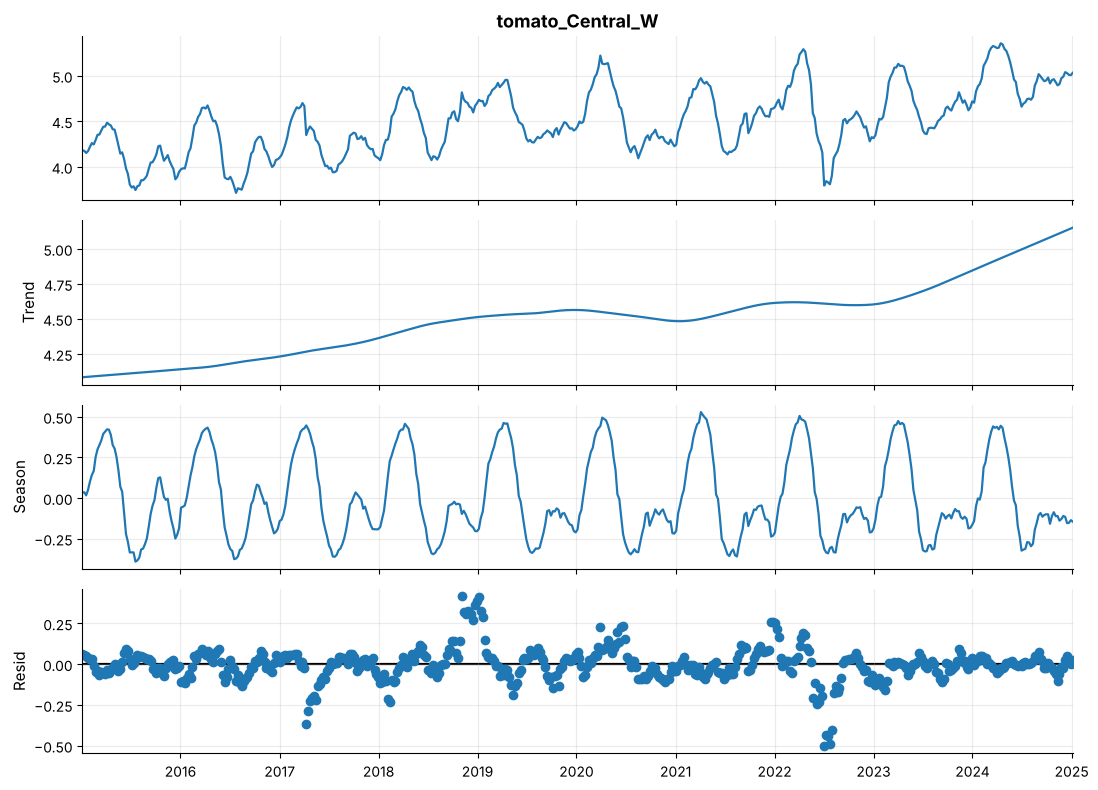

In [5]:
weekly = ag.price_series("tomato", "Central", freq="W")
stl = STL(np.log(weekly), period=52, robust=True).fit()      # log => multiplicative becomes additive
fig = stl.plot(); fig.set_size_inches(11, 8); plt.tight_layout(); plt.show()

How to read it: **top** = log price, then **trend**, **seasonal**, and **resid** (the remainder = cycle + noise).
Notice the residual panel is *not* pure noise: the shock spikes survive. A decomposition never explains everything; it tells you **what is left to model**.

**How seasonal is a series?: a number you can compute.** Hyndman's *strength of seasonality*:
$$F_S = \max\left(0,\; 1 - \frac{\operatorname{Var}(R_t)}{\operatorname{Var}(S_t + R_t)}\right)$$
near 0 = no seasonality, near 1 = very seasonal.

In [6]:
def seasonal_strength(series, period=52):
    res = STL(np.log(series), period=period, robust=True).fit()
    return float(max(0.0, 1 - res.resid.var() / (res.seasonal + res.resid).var()))

print("Tomato seasonal strength:", round(seasonal_strength(weekly), 3))

Tomato seasonal strength: 0.858


---
### 🧩 Exercise 1: Which crop is most seasonal?  ⭐

Use `seasonal_strength` on the **weekly Central-market** series for all four commodities
(`maize`, `tomato`, `onion`, `potato`). Store the results in a dict called `strengths`
(`{"maize": 0.xx, ...}`) and store the name of the most seasonal crop in `most_seasonal`.

<details><summary>💡 Hint 1: gentle nudge</summary>

Loop over `ag.COMMODITIES`. For each name, build the weekly series with `ag.price_series(name, 'Central', freq='W')`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Inside the loop: `strengths[name] = seasonal_strength(series)`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`most_seasonal = max(strengths, key=strengths.get)` finds the key with the largest value.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [7]:
strengths = {}
for name in ag.COMMODITIES:
    s = ag.price_series(name, "Central", freq="W")
    strengths[name] = seasonal_strength(s)
most_seasonal = max(strengths, key=strengths.get)
print({k: round(v, 3) for k, v in strengths.items()}, "->", most_seasonal)

{'maize': 0.797, 'tomato': 0.858, 'onion': 0.803, 'potato': 0.792} -> tomato


In [8]:
ag.check("strengths has all 4 crops", isinstance(strengths, dict) and set(strengths) == set(ag.COMMODITIES))
ag.check("values are between 0 and 1", all(0 <= v <= 1 for v in strengths.values()))
ag.check("most_seasonal is the arg-max", most_seasonal == max(strengths, key=strengths.get),
         "use max(strengths, key=strengths.get)")

✅  strengths has all 4 crops
✅  values are between 0 and 1
✅  most_seasonal is the arg-max


True

---
## 3 · Stationarity: the property models crave

A series is (weakly) **stationary** if its statistical behaviour doesn't depend on *when* you look:

1. constant **mean**,
2. constant **variance**,
3. autocovariance depends only on the **lag** between two points, not on their position in time.

Why do we care? A model learned on "the past" can only describe "the future" if the rules didn't change.
A trending series has a different mean every year: there's nothing stable to learn. ARIMA-family models
*require* stationarity; machine-learning models cope better but still benefit from it.

**Eyeball test:** compare rolling mean and rolling standard deviation.

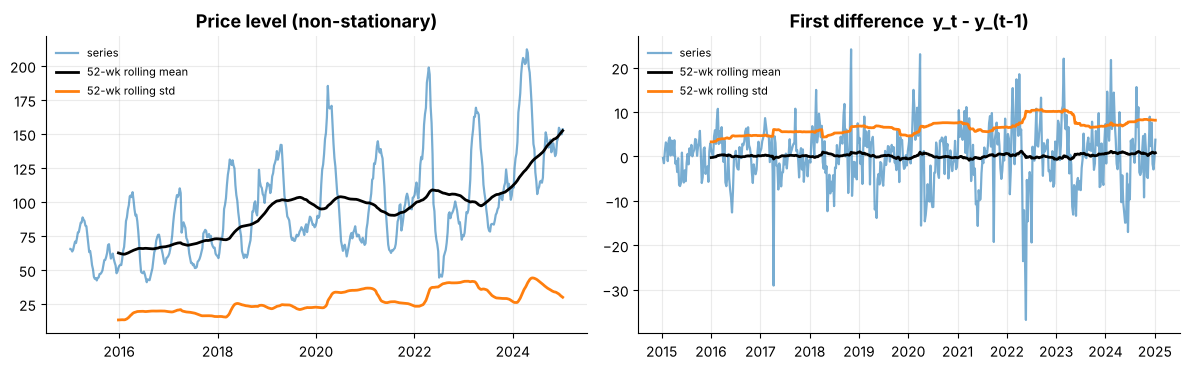

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (title, y) in zip(axes, [("Price level (non-stationary)", weekly),
                                  ("First difference  y_t - y_(t-1)", weekly.diff().dropna())]):
    ax.plot(y, alpha=0.6, label="series")
    ax.plot(y.rolling(52).mean(), color="k", lw=2, label="52-wk rolling mean")
    ax.plot(y.rolling(52).std(), color="tab:orange", lw=2, label="52-wk rolling std")
    ax.set_title(title); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Left: the black mean line wanders. Right: it hugs zero. **Differencing**: subtracting the previous value:
removes trend by modelling *changes* instead of *levels*.

### Formal tests: ADF and KPSS

| Test | Null hypothesis $H_0$ | Reject $H_0$ (small p) means… |
|---|---|---|
| **ADF** (Augmented Dickey-Fuller) | series has a **unit root** (non-stationary) | looks **stationary** ✅ |
| **KPSS** | series **is** stationary | looks **non-stationary** ❌ |

They ask opposite questions on purpose: use both. Rule of thumb: *ADF p < 0.05 and KPSS p > 0.05 → stationary.*

In [10]:
def stationarity_report(y, name=""):
    y = pd.Series(y).dropna()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        adf_p = adfuller(y, autolag="AIC")[1]
        kpss_p = kpss(y, regression="c", nlags="auto")[1]
    verdict = "stationary" if (adf_p < 0.05 and kpss_p > 0.05) else "NOT stationary (or inconclusive)"
    print(f"{name:32s} ADF p={adf_p:.4f} | KPSS p={kpss_p:.4f}  ->  {verdict}")

stationarity_report(weekly, "weekly price level")
stationarity_report(np.log(weekly), "weekly log price")
stationarity_report(np.log(weekly).diff(), "weekly log-return (1st diff of log)")
stationarity_report(np.log(weekly).diff(52), "52-week seasonal difference of log")

weekly price level               ADF p=0.0663 | KPSS p=0.0100  ->  NOT stationary (or inconclusive)
weekly log price                 ADF p=0.1255 | KPSS p=0.0100  ->  NOT stationary (or inconclusive)
weekly log-return (1st diff of log) ADF p=0.0000 | KPSS p=0.1000  ->  stationary
52-week seasonal difference of log ADF p=0.0436 | KPSS p=0.1000  ->  stationary


> 💡 **Professor's aside.** The first difference of the **log** price is (approximately) the *percentage change*: a **return**. Finance people live in returns; agricultural economists should too. A 2-unit move means a lot at price 20, little at price 200.

> ⚠️ **Common pitfall.** Passing a stationarity test on the raw series does **not** mean no seasonality. ADF is not a seasonality detector; check seasonal differencing (`diff(52)` weekly / `diff(12)` monthly) and the ACF too.

---
### 🧩 Exercise 2: Make it stationary  ⭐

Using the weekly **maize** series at the Central market:
1. Build `maize_w` and compute its ADF p-value on the raw levels → `p_levels`.
2. Take the first difference of the **log** series and compute the ADF p-value → `p_diff`.
3. Set `needs_differencing = True` if `p_levels > 0.05 and p_diff < 0.05`, else `False`.

<details><summary>💡 Hint 1: gentle nudge</summary>

`adfuller(x)[1]` returns the p-value. Remember to `.dropna()` after `.diff()` (the first value is NaN).

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

log-difference: `np.log(maize_w).diff().dropna()`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Both p-values go in plain floats; then a one-line boolean expression for `needs_differencing`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [11]:
maize_w = ag.price_series("maize", "Central", freq="W")
p_levels = adfuller(maize_w)[1]
p_diff = adfuller(np.log(maize_w).diff().dropna())[1]
needs_differencing = bool(p_levels > 0.05 and p_diff < 0.05)
print(round(p_levels, 4), round(p_diff, 6), needs_differencing)

0.1316 0.0 True


In [12]:
ag.check("p-values are floats in [0,1]", all(isinstance(p, float) and 0 <= p <= 1 for p in (p_levels, p_diff)))
ag.check("the differenced series is clearly stationary (p < 0.05)", p_diff < 0.05)
ag.check("needs_differencing matches your p-values", needs_differencing == (p_levels > 0.05 and p_diff < 0.05))

✅  p-values are floats in [0,1]
✅  the differenced series is clearly stationary (p < 0.05)
✅  needs_differencing matches your p-values


True

---
## 4 · Autocorrelation: how the past echoes

A **lag observation** is just an earlier value: $y_{t-1}$ is "lag 1", $y_{t-7}$ is "lag 7".
**Autocorrelation at lag $k$** is the correlation between $y_t$ and $y_{t-k}$:

$$\rho_k = \frac{\sum_{t=k+1}^{T} (y_t-\bar y)(y_{t-k}-\bar y)}{\sum_{t=1}^{T}(y_t-\bar y)^2}$$

Start with the picture: a **lag plot** puts $y_{t-1}$ on the x-axis and $y_t$ on the y-axis.

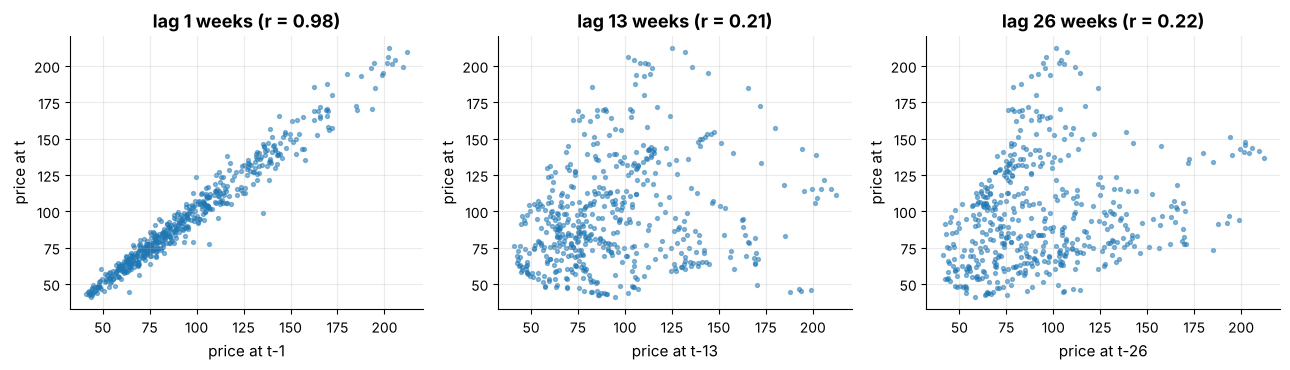

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, k in zip(axes, [1, 13, 26]):
    ax.scatter(weekly.shift(k), weekly, s=8, alpha=0.5)
    r = weekly.corr(weekly.shift(k))
    ax.set(title=f"lag {k} weeks (r = {r:.2f})", xlabel=f"price at t-{k}", ylabel="price at t")
plt.tight_layout(); plt.show()

A tight diagonal cloud at lag 1 means *"this week ≈ last week"*: **persistence**. This is why the
simplest forecast ("tomorrow = today") is so hard to beat, and why every model you'll build must prove it beats that baseline.

### ACF: all lags at once

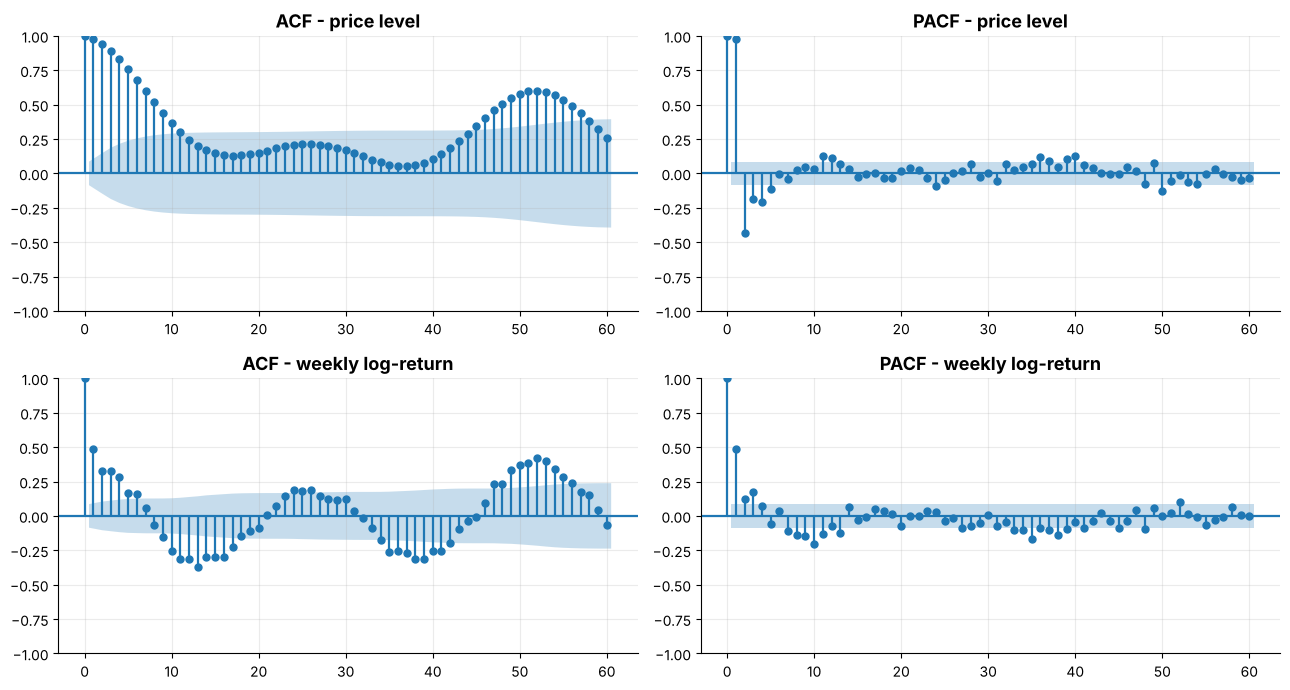

In [14]:
logret = np.log(weekly).diff().dropna()
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
plot_acf(weekly, lags=60, ax=axes[0, 0], title="ACF - price level")
plot_pacf(weekly, lags=60, ax=axes[0, 1], title="PACF - price level", method="ywm")
plot_acf(logret, lags=60, ax=axes[1, 0], title="ACF - weekly log-return")
plot_pacf(logret, lags=60, ax=axes[1, 1], title="PACF - weekly log-return", method="ywm")
plt.tight_layout(); plt.show()

**Reading these plots**: the blue band is a 95 % significance zone ($\approx \pm 1.96/\sqrt{T}$): bars outside the band are "real".

| Pattern you see | What it usually means |
|---|---|
| ACF decays **very slowly** (like the top-left) | non-stationary / strong trend → difference it |
| ACF **bumps recur** every 52 lags | yearly seasonality |
| ACF tails off, **PACF cuts off** after lag *p* | **AR(p)** process |
| **ACF cuts off** after lag *q*, PACF tails off | **MA(q)** process |
| both tail off | **ARMA**: mixed |

### ACF vs PACF in one sentence
The **ACF** at lag 3 measures *all* the connection between today and three weeks ago, including the route that passes through lags 1 and 2.
The **PACF** at lag 3 asks: *after accounting for lags 1 and 2, is there anything left?*: the **direct** link.

Let's verify we truly understand ACF by computing it by hand:

In [15]:
def acf_by_hand(x, k):
    x = np.asarray(x, float)
    xm = x - x.mean()
    return np.sum(xm[k:] * xm[:-k]) / np.sum(xm ** 2) if k > 0 else 1.0

mine = [acf_by_hand(weekly, k) for k in range(1, 6)]
theirs = acf(weekly, nlags=5)[1:]
print(np.round(mine, 4)); print(np.round(theirs, 4))

[0.9797 0.9424 0.8928 0.8307 0.7589]
[0.9797 0.9424 0.8928 0.8307 0.7589]


---
### 🧩 Exercise 3: Build your own ACF and compare  ⭐⭐

Write `acf_values(x, max_lag)` that returns a NumPy array of autocorrelations for lags **1..max_lag**
using the formula above (re-use the idea of `acf_by_hand`, but your function should handle the whole range).
Apply it to `logret` (weekly log-returns) with `max_lag=10` and store the result in `my_acf`.
Then find the lag with the largest **absolute** autocorrelation (1-based) in `peak_lag`.

<details><summary>💡 Hint 1: gentle nudge</summary>

A list comprehension `[... for k in range(1, max_lag + 1)]` works nicely.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Subtract the mean *once*, before the loop. Then: `np.sum(xm[k:] * xm[:-k]) / np.sum(xm**2)`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`peak_lag = int(np.argmax(np.abs(my_acf))) + 1`: the `+1` is because lag numbering starts at 1 but arrays start at 0.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [16]:
def acf_values(x, max_lag):
    x = np.asarray(x, float)
    xm = x - x.mean()
    denom = np.sum(xm ** 2)
    return np.array([np.sum(xm[k:] * xm[:-k]) / denom for k in range(1, max_lag + 1)])

my_acf = acf_values(logret, 10)
peak_lag = int(np.argmax(np.abs(my_acf))) + 1
print(np.round(my_acf, 3), "| peak lag:", peak_lag)

[ 0.485  0.327  0.33   0.286  0.169  0.158  0.056 -0.064 -0.152 -0.258] | peak lag: 1


In [17]:
ref = acf(logret, nlags=10)[1:]
ag.check("returns 10 values", my_acf is not None and len(my_acf) == 10)
ag.check("matches statsmodels' acf (within 1e-6)", my_acf is not None and np.allclose(my_acf, ref, atol=1e-6),
         "denominator is the sum of squares of the *whole* de-meaned series")
ag.check("peak_lag is correct", peak_lag == int(np.argmax(np.abs(ref))) + 1)

✅  returns 10 values
✅  matches statsmodels' acf (within 1e-6)
✅  peak_lag is correct


True

---
### 🧩 Exercise 4: Read the PACF like a forecaster  ⭐⭐

Compute the PACF of `logret` for 20 lags (`pacf(..., nlags=20, method="ywm")`).
Find all lags (1..20) whose absolute PACF exceeds the 95 % bound `1.96 / sqrt(len(logret))`
and store them as a list `sig_lags`. Based on that list, set `suggested_ar_order` to the **largest
significant lag among 1-4** (a rough first guess for an AR order; 0 if none).

<details><summary>💡 Hint 1: gentle nudge</summary>

`vals = pacf(logret, nlags=20, method='ywm')`; `vals[0]` is lag 0 (always 1): skip it.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`bound = 1.96 / np.sqrt(len(logret))`; `sig_lags = [k for k in range(1, 21) if abs(vals[k]) > bound]`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`suggested_ar_order = max([k for k in sig_lags if k <= 4], default=0)`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [18]:
vals = pacf(logret, nlags=20, method="ywm")
bound = 1.96 / np.sqrt(len(logret))
sig_lags = [k for k in range(1, 21) if abs(vals[k]) > bound]
suggested_ar_order = max([k for k in sig_lags if k <= 4], default=0)
print("significant lags:", sig_lags, "| suggested AR order:", suggested_ar_order)

significant lags: [1, 2, 3, 7, 8, 9, 10, 11, 13] | suggested AR order: 3


In [19]:
ag.check("sig_lags is a list of ints between 1 and 20", isinstance(sig_lags, list) and all(1 <= k <= 20 for k in sig_lags))
ag.check("lag 1 is significant for these returns", 1 in sig_lags, "returns still carry short-term momentum")
ag.check("suggested_ar_order is consistent with sig_lags",
         suggested_ar_order == max([k for k in sig_lags if k <= 4], default=0))

✅  sig_lags is a list of ints between 1 and 20
✅  lag 1 is significant for these returns
✅  suggested_ar_order is consistent with sig_lags


True

---
## 5 · A glimpse of a "random walk" (the thing to beat)

If $y_t = y_{t-1} + \varepsilon_t$ the series is a **random walk**: the best forecast is *today's value*. Many
real price series are close to this. Let's see how a random walk looks next to ours.

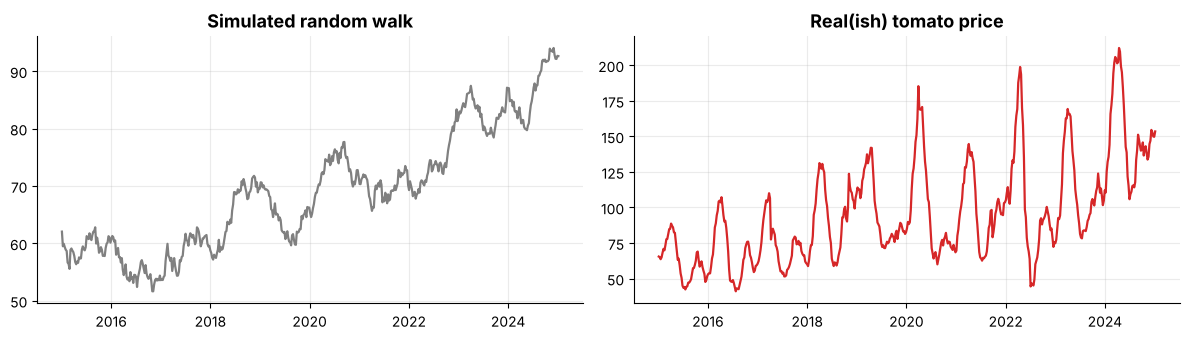

random walk level                ADF p=0.9596 | KPSS p=0.0100  ->  NOT stationary (or inconclusive)
random walk differenced          ADF p=0.0000 | KPSS p=0.1000  ->  stationary


In [20]:
rw = pd.Series(np.cumsum(np.random.default_rng(3).normal(0, 1, len(weekly))) + 60, index=weekly.index)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=False)
axes[0].plot(rw, color="gray"); axes[0].set_title("Simulated random walk")
axes[1].plot(weekly, color="tab:red"); axes[1].set_title("Real(ish) tomato price")
plt.tight_layout(); plt.show()
stationarity_report(rw, "random walk level"); stationarity_report(rw.diff(), "random walk differenced")

The random walk can't be told apart from our price at a glance: **that's the point**: a model must earn its keep by
capturing the *seasonal* and *driver-based* structure the random walk lacks.

---
## 🎓 Mini-quiz (answers collapsed)
1. A series has a 7-day pattern and a 365-day pattern. How many seasonal periods is that?
2. ADF p = 0.30. Is the series stationary?
3. Why do we difference the **log** price rather than the raw price?

<details><summary>Answers</summary>

1. Two (weekly and yearly): "multiple seasonality". SARIMA handles one; ML/Fourier features handle several.
2. No evidence of stationarity: we *fail to reject* the unit-root null. Difference it and re-test.
3. Logging stabilises variance (multiplicative → additive); differencing the log gives approximate *percentage* changes.
</details>

        ---
        ## 🧾 Recap
        - A time series is data where **order carries information**: never shuffle it.
- Decompose into **trend + seasonality + cycle + noise**; use logs when swings scale with level.
- **Stationarity** (stable mean/variance/autocovariance) is achieved by differencing, tested by ADF + KPSS.
- **ACF** = total correlation with lag *k*; **PACF** = direct correlation after removing intermediate lags.
- Persistence is strong: any model must beat the 'tomorrow = today' baseline.

**Next up:** Lesson 7.2: turning raw, messy records into a clean, regular, feature-rich time-series table.